# BÀI TẬP THỰC HÀNH LAB 1 - PHẦN 2 - BÀI 6 (TRANG 45)
## Khai phá tập phổ biến trên Groceries Dataset: So sánh Apriori và FP-Growth

**Thông tin bài tập (Tài liệu LAB1, trang 45):**
Cho mẫu dữ liệu **Groceries Dataset** (`groceries.csv`) về các giao dịch trong một tháng của một cửa hàng outlet, gồm **9,835 giao dịch** và **169 mặt hàng (items)**. Với `min_sup` từ `0.01` đến `0.1`, thực hiện:
- **Câu a:** Tìm tất cả các tập phổ biến trong từng trường hợp bằng giải thuật **Apriori** (`mlxtend`) và ghi nhận thời gian xử lý. Sử dụng `TransactionEncoder` để chuyển dữ liệu về dạng one-hot encoding trước khi đưa vào thuật toán.
- **Câu b:** Tìm tất cả các tập phổ biến trong từng trường hợp bằng giải thuật **FP-Growth** (`mlxtend`), ghi nhận thời gian xử lý và đối chiếu kết quả với Apriori.
- **Câu c:** Vẽ biểu đồ so sánh thời gian xử lý của hai thuật toán và đưa ra nhận xét, giải thích.

> **Lưu ý quan trọng về thông số `min_sup` trong đề bài PDF (Trang 45):**
> Tài liệu PDF ghi `"Với min_sup từ 0.01% đến 0.1%"`, tuy nhiên trong thư viện `mlxtend`, tham số `min_support` nhận giá trị tỷ lệ thập phân trong đoạn `(0, 1]`, nên dải giá trị hợp lý tương ứng là **từ `0.01` (1%) đến `0.1` (10%)** (tương ứng tối thiểu `99` đến `984` giao dịch trong tổng số `9,835` giao dịch).
> Nếu truyền đúng nghĩa đen `0.01% = 0.0001`, ngưỡng đếm tối thiểu sẽ là $\lceil 0.0001 \times 9835 \rceil = 1$ giao dịch. Khi đó toàn bộ `169` mặt hàng đều là phổ biến và giỏ hàng dài nhất có tới `32` mặt hàng sẽ gây **bùng nổ tổ hợp** ($2^{32} - 1 \approx 4.29 \times 10^9$ tập con), tràn bộ nhớ và không mang ý nghĩa khai phá. Vì vậy bài làm sử dụng dải ngưỡng **`min_sup_list = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]`** (từ 1% đến 10%).

In [1]:
import csv
import gc
import importlib.util
import math
import os
import subprocess
import sys
import time

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
print(f"{STUDENT_NAME} - {MSSV}")

# Cài đặt mlxtend nếu chưa có (chạy an toàn cả trên Google Colab và máy cục bộ)
if importlib.util.find_spec("mlxtend") is None:
    print("Đang cài đặt thư viện mlxtend...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend"])

import matplotlib.pyplot as plt
import mlxtend
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"


def get_dataset_path(filename="groceries.csv"):
    """Tìm đường dẫn dataset ưu tiên: cục bộ ./Dataset -> Google Drive (Colab) -> gdown."""
    local_path = os.path.join(".", "Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    if importlib.util.find_spec("gdown") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    os.makedirs("Dataset", exist_ok=True)
    # Fallback tải toàn bộ thư mục Dataset từ Google Drive bằng gdown:
    # gdown --folder https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing -O Dataset
    subprocess.check_call(
        [sys.executable, "-m", "gdown", "--folder", DRIVE_FOLDER_URL, "-O", "Dataset"]
    )
    if os.path.exists(local_path):
        return local_path
    for root, _, files in os.walk("Dataset"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu: {filename}")


data_path = get_dataset_path("groceries.csv")
print(f"Đường dẫn dữ liệu: {data_path}")
print(f"Phiên bản thư viện -> pandas: {pd.__version__}, mlxtend: {mlxtend.__version__}, seaborn: {sns.__version__}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn dữ liệu: .\Dataset\groceries.csv
Phiên bản thư viện -> pandas: 3.1.1, mlxtend: 0.25.0, seaborn: 0.13.2


## Tiền xử lý dữ liệu và mã hóa One-Hot bằng `TransactionEncoder`

Tệp `groceries.csv` lưu mỗi giao dịch trên một dòng với số lượng mặt hàng thay đổi (không có dòng tiêu đề). Ta đọc từng dòng thành danh sách các mặt hàng, sau đó dùng `mlxtend.preprocessing.TransactionEncoder` để biến đổi về DataFrame nhị phân (`bool`) kích thước `(9835, 169)` sẵn sàng cho `apriori` và `fpgrowth`.

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

with open(data_path, "r", encoding="utf-8") as f:
    transactions = [[item.strip() for item in row if item.strip()] for row in csv.reader(f)]
transactions = [t for t in transactions if t]

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_ohe = pd.DataFrame(te_ary, columns=te.columns_)

txn_lengths = [len(t) for t in transactions]
item_counts = df_ohe.sum(axis=0).sort_values(ascending=False)
top10_items = pd.DataFrame(
    {
        "item": item_counts.head(10).index,
        "count": item_counts.head(10).values,
        "support": (item_counts.head(10).values / len(df_ohe)).round(4),
    }
)

print(f"Tổng số giao dịch: {len(transactions):,}")
print(f"Tổng số mặt hàng duy nhất: {len(te.columns_):,}")
print(f"Kích thước DataFrame One-Hot: {df_ohe.shape} | kiểu dữ liệu: {df_ohe.dtypes.unique().tolist()}")
print(
    f"Số mặt hàng/giao dịch -> min: {min(txn_lengths)}, max: {max(txn_lengths)}, "
    f"trung bình: {np.mean(txn_lengths):.2f}"
)
print("\nTop 10 mặt hàng xuất hiện nhiều nhất:")
print(top10_items.to_string(index=False))

print(
    "\n[Lưu ý PDF trang 45] PDF ghi '0.01% đến 0.1%', tương ứng trong mlxtend là "
    "min_support từ 0.01 đến 0.1 (1% đến 10%). Nếu dùng 0.0001 (0.01%) sẽ tương đương "
    "support_count >= 1 trên các giỏ hàng dài tối đa 32 mặt hàng -> bùng nổ tổ hợp (2^32 - 1 tập con)."
)

Nguyễn Phạm Bảo Khanh - 6451071033
Tổng số giao dịch: 9,835
Tổng số mặt hàng duy nhất: 169
Kích thước DataFrame One-Hot: (9835, 169) | kiểu dữ liệu: [dtype('bool')]
Số mặt hàng/giao dịch -> min: 1, max: 32, trung bình: 4.41

Top 10 mặt hàng xuất hiện nhiều nhất:
            item  count  support
      whole milk   2513   0.2555
other vegetables   1903   0.1935
      rolls/buns   1809   0.1839
            soda   1715   0.1744
          yogurt   1372   0.1395
   bottled water   1087   0.1105
 root vegetables   1072   0.1090
  tropical fruit   1032   0.1049
   shopping bags    969   0.0985
         sausage    924   0.0940

[Lưu ý PDF trang 45] PDF ghi '0.01% đến 0.1%', tương ứng trong mlxtend là min_support từ 0.01 đến 0.1 (1% đến 10%). Nếu dùng 0.0001 (0.01%) sẽ tương đương support_count >= 1 trên các giỏ hàng dài tối đa 32 mặt hàng -> bùng nổ tổ hợp (2^32 - 1 tập con).


## Câu a: Tìm tất cả các tập phổ biến bằng giải thuật Apriori

Thực hiện `apriori(df_ohe, min_support=..., use_colnames=True)` trên 6 ngưỡng `min_sup_list = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]`. Thời gian xử lý được đo bằng `time.perf_counter()` (trung bình qua `5` lần lặp sau 1 lần khởi động warm-up và `gc.collect()` ngoài vòng đo để hạn chế nhiễu).

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

min_sup_list = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]
N_REPEATS = 5
n_txns = len(df_ohe)

# Warm-up trước khi đo thời gian
_ = apriori(df_ohe, min_support=0.1, use_colnames=True)

apriori_records = []
apriori_results = {}

for ms in min_sup_list:
    timings = []
    res_df = None
    for _ in range(N_REPEATS):
        gc.collect()
        t0 = time.perf_counter()
        res_df = apriori(df_ohe, min_support=ms, use_colnames=True)
        timings.append(time.perf_counter() - t0)

    apriori_results[ms] = res_df
    itemset_lens = res_df["itemsets"].str.len()
    apriori_records.append(
        {
            "min_support": ms,
            "min_sup_pct": f"{ms * 100:.0f}%",
            "min_count": math.ceil(ms * n_txns),
            "num_itemsets": len(res_df),
            "max_len": int(itemset_lens.max()) if len(res_df) > 0 else 0,
            "apriori_mean_s": float(np.mean(timings)),
            "apriori_min_s": float(np.min(timings)),
        }
    )

df_apriori_summary = pd.DataFrame(apriori_records)
print("=== KẾT QUẢ APRIORI THEO TỪNG NGƯỠNG MIN_SUPPORT ===")
print(df_apriori_summary.to_string(index=False))

print("\n=== TOP 15 TẬP PHỔ BIẾN (APRIORI, min_support = 0.01) ===")
ap_001 = apriori_results[0.01].sort_values(by="support", ascending=False).copy()
ap_001["length"] = ap_001["itemsets"].str.len()
ap_001["items"] = ap_001["itemsets"].apply(lambda x: ", ".join(sorted(list(x))))
print(ap_001[["support", "length", "items"]].head(15).to_string(index=False))

print("\n=== TOP 10 TẬP PHỔ BIẾN BẬC >= 2 (APRIORI, min_support = 0.01) ===")
print(ap_001[ap_001["length"] >= 2][["support", "length", "items"]].head(10).to_string(index=False))

Nguyễn Phạm Bảo Khanh - 6451071033
=== KẾT QUẢ APRIORI THEO TỪNG NGƯỠNG MIN_SUPPORT ===
 min_support min_sup_pct  min_count  num_itemsets  max_len  apriori_mean_s  apriori_min_s
        0.01          1%         99           333        3        0.085625       0.076248
        0.02          2%        197           122        3        0.035771       0.033152
        0.03          3%        296            63        2        0.018962       0.016948
        0.05          5%        492            31        2        0.010219       0.008376
        0.07          7%        689            19        2        0.006921       0.005238
        0.10         10%        984             8        1        0.003441       0.002584

=== TOP 15 TẬP PHỔ BIẾN (APRIORI, min_support = 0.01) ===
 support  length            items
0.255516       1       whole milk
0.193493       1 other vegetables
0.183935       1       rolls/buns
0.174377       1             soda
0.139502       1           yogurt
0.110524       1   

## Câu b: Tìm tất cả các tập phổ biến bằng giải thuật FP-Growth

Thực hiện `fpgrowth(df_ohe, min_support=..., use_colnames=True)` trên cùng danh sách `min_sup_list = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]`, đo thời gian xử lý tương tự (trung bình `5` lần lặp sau warm-up) và kiểm tra đối chiếu sự trùng khớp chính xác về tập phổ biến cũng như giá trị support so với Apriori.

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

# Warm-up trước khi đo thời gian
_ = fpgrowth(df_ohe, min_support=0.1, use_colnames=True)

fpgrowth_records = []
fpgrowth_results = {}

for ms in min_sup_list:
    timings = []
    res_df = None
    for _ in range(N_REPEATS):
        gc.collect()
        t0 = time.perf_counter()
        res_df = fpgrowth(df_ohe, min_support=ms, use_colnames=True)
        timings.append(time.perf_counter() - t0)

    fpgrowth_results[ms] = res_df

    # Kiểm chứng khớp chính xác với kết quả của Apriori
    ap_map = dict(zip(apriori_results[ms]["itemsets"], apriori_results[ms]["support"]))
    fp_map = dict(zip(res_df["itemsets"], res_df["support"]))
    sets_match = set(ap_map.keys()) == set(fp_map.keys())
    supports_match = sets_match and all(
        math.isclose(ap_map[k], fp_map[k], rel_tol=0.0, abs_tol=1e-12) for k in ap_map
    )
    assert sets_match and supports_match, f"Kết quả FP-Growth khác Apriori tại min_support={ms}!"

    fpgrowth_records.append(
        {
            "min_support": ms,
            "min_sup_pct": f"{ms * 100:.0f}%",
            "num_itemsets": len(res_df),
            "match_apriori": bool(sets_match and supports_match),
            "fpgrowth_mean_s": float(np.mean(timings)),
            "fpgrowth_min_s": float(np.min(timings)),
        }
    )

df_fpgrowth_summary = pd.DataFrame(fpgrowth_records)
print("=== KẾT QUẢ FP-GROWTH THEO TỪNG NGƯỠNG MIN_SUPPORT ===")
print(df_fpgrowth_summary.to_string(index=False))

print("\n=== TOP 15 TẬP PHỔ BIẾN (FP-GROWTH, min_support = 0.01) ===")
fp_001 = fpgrowth_results[0.01].sort_values(by="support", ascending=False).copy()
fp_001["length"] = fp_001["itemsets"].str.len()
fp_001["items"] = fp_001["itemsets"].apply(lambda x: ", ".join(sorted(list(x))))
print(fp_001[["support", "length", "items"]].head(15).to_string(index=False))

Nguyễn Phạm Bảo Khanh - 6451071033
=== KẾT QUẢ FP-GROWTH THEO TỪNG NGƯỠNG MIN_SUPPORT ===
 min_support min_sup_pct  num_itemsets  match_apriori  fpgrowth_mean_s  fpgrowth_min_s
        0.01          1%           333           True         0.071449        0.064199
        0.02          2%           122           True         0.058949        0.055819
        0.03          3%            63           True         0.044973        0.041701
        0.05          5%            31           True         0.034419        0.030918
        0.07          7%            19           True         0.029983        0.025730
        0.10         10%             8           True         0.023767        0.022135

=== TOP 15 TẬP PHỔ BIẾN (FP-GROWTH, min_support = 0.01) ===
 support  length            items
0.255516       1       whole milk
0.193493       1 other vegetables
0.183935       1       rolls/buns
0.174377       1             soda
0.139502       1           yogurt
0.110524       1    bottled water
0.

## Câu c: Biểu đồ so sánh thời gian xử lý Apriori và FP-Growth

Tổng hợp bảng so sánh hiệu năng trên dải `min_support` từ `0.01` đến `0.1`, trực quan hóa bằng biểu đồ đường (Line Plot) kết hợp biểu đồ cột nhóm (Grouped Bar Chart), đồng thời kiểm chứng mở rộng ở các ngưỡng thấp hơn (`0.003`, `0.005`) để quan sát điểm giao cắt hiệu năng giữa hai thuật toán.

Nguyễn Phạm Bảo Khanh - 6451071033
=== BẢNG SO SÁNH THỜI GIAN XỬ LÝ APRIORI VS FP-GROWTH (0.01 -> 0.10) ===
 min_support min_sup_pct  num_itemsets  max_len  apriori_ms  fpgrowth_ms faster_algo  speed_ratio  match_apriori
        0.01          1%           333        3       85.62        71.45   FP-Growth         1.20           True
        0.02          2%           122        3       35.77        58.95     Apriori         1.65           True
        0.03          3%            63        2       18.96        44.97     Apriori         2.37           True
        0.05          5%            31        2       10.22        34.42     Apriori         3.37           True
        0.07          7%            19        2        6.92        29.98     Apriori         4.33           True
        0.10         10%             8        1        3.44        23.77     Apriori         6.91           True


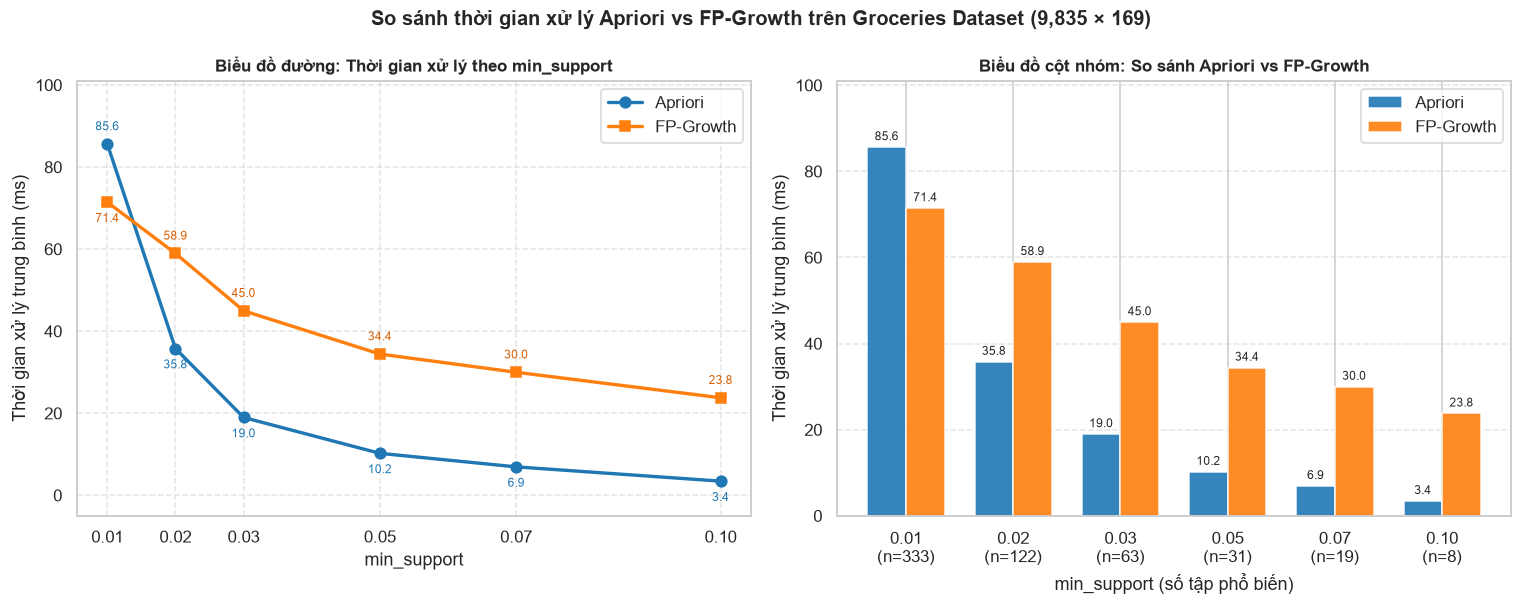


=== KIỂM CHỨNG MỞ RỘNG Ở NGƯỠNG THẤP (0.003 -> 0.01) ===
min_support  num_itemsets apriori_ms fpgrowth_ms speedup_fp
      0.003          2226     421.07      137.75       3.06
      0.005          1001     189.97       96.95       1.96
      0.010           333      82.58       77.47       1.07


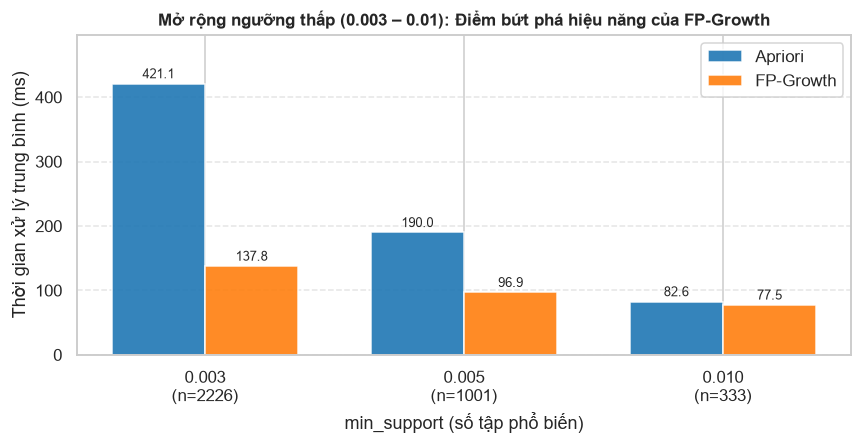

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

df_compare = pd.merge(
    df_apriori_summary[["min_support", "min_sup_pct", "num_itemsets", "max_len", "apriori_mean_s", "apriori_min_s"]],
    df_fpgrowth_summary[["min_support", "fpgrowth_mean_s", "fpgrowth_min_s", "match_apriori"]],
    on="min_support",
)
df_compare["apriori_ms"] = df_compare["apriori_mean_s"] * 1000.0
df_compare["fpgrowth_ms"] = df_compare["fpgrowth_mean_s"] * 1000.0
df_compare["faster_algo"] = np.where(
    df_compare["fpgrowth_ms"] < df_compare["apriori_ms"], "FP-Growth", "Apriori"
)
df_compare["speed_ratio"] = np.maximum(
    df_compare["apriori_ms"] / df_compare["fpgrowth_ms"],
    df_compare["fpgrowth_ms"] / df_compare["apriori_ms"],
).round(2)

print("=== BẢNG SO SÁNH THỜI GIAN XỬ LÝ APRIORI VS FP-GROWTH (0.01 -> 0.10) ===")
print(
    df_compare[
        [
            "min_support",
            "min_sup_pct",
            "num_itemsets",
            "max_len",
            "apriori_ms",
            "fpgrowth_ms",
            "faster_algo",
            "speed_ratio",
            "match_apriori",
        ]
    ].to_string(index=False, float_format=lambda v: f"{v:.2f}")
)

# Biểu đồ chính: Line Plot + Grouped Bar Chart trên [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# 1. Line plot
ax1 = axes[0]
ax1.plot(
    df_compare["min_support"],
    df_compare["apriori_ms"],
    marker="o",
    linewidth=2.2,
    markersize=7,
    label="Apriori",
    color="#1f77b4",
)
ax1.plot(
    df_compare["min_support"],
    df_compare["fpgrowth_ms"],
    marker="s",
    linewidth=2.2,
    markersize=7,
    label="FP-Growth",
    color="#ff7f0e",
)
for _, row in df_compare.iterrows():
    ap_y = row["apriori_ms"]
    fp_y = row["fpgrowth_ms"]
    ap_dy = 9 if ap_y >= fp_y else -13
    fp_dy = 9 if fp_y > ap_y else -13
    ax1.annotate(
        f"{ap_y:.1f}",
        (row["min_support"], ap_y),
        textcoords="offset points",
        xytext=(0, ap_dy),
        ha="center",
        fontsize=8,
        color="#1f77b4",
    )
    ax1.annotate(
        f"{fp_y:.1f}",
        (row["min_support"], fp_y),
        textcoords="offset points",
        xytext=(0, fp_dy),
        ha="center",
        fontsize=8,
        color="#d95f02",
    )
y_max_line = max(df_compare["apriori_ms"].max(), df_compare["fpgrowth_ms"].max())
ax1.set_ylim(-5, y_max_line * 1.18)
ax1.set_title("Biểu đồ đường: Thời gian xử lý theo min_support", fontsize=11, fontweight="bold")
ax1.set_xlabel("min_support")
ax1.set_ylabel("Thời gian xử lý trung bình (ms)")
ax1.set_xticks(df_compare["min_support"])
ax1.set_xticklabels([f"{s:.2f}" for s in df_compare["min_support"]])
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 2. Grouped bar chart
ax2 = axes[1]
x = np.arange(len(df_compare))
width = 0.36
bars1 = ax2.bar(
    x - width / 2,
    df_compare["apriori_ms"],
    width,
    label="Apriori",
    color="#1f77b4",
    alpha=0.9,
)
bars2 = ax2.bar(
    x + width / 2,
    df_compare["fpgrowth_ms"],
    width,
    label="FP-Growth",
    color="#ff7f0e",
    alpha=0.9,
)
for bar in bars1:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}", ha="center", va="bottom", fontsize=8)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}", ha="center", va="bottom", fontsize=8)

ax2.set_title("Biểu đồ cột nhóm: So sánh Apriori vs FP-Growth", fontsize=11, fontweight="bold")
ax2.set_xlabel("min_support (số tập phổ biến)")
ax2.set_ylabel("Thời gian xử lý trung bình (ms)")
ax2.set_xticks(x)
ax2.set_xticklabels(
    [f"{row['min_support']:.2f}\n(n={row['num_itemsets']})" for _, row in df_compare.iterrows()]
)
ax2.set_ylim(0, y_max_line * 1.18)
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)
ax2.legend()

fig.suptitle(
    "So sánh thời gian xử lý Apriori vs FP-Growth trên Groceries Dataset (9,835 × 169)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Kiểm chứng bổ sung ở ngưỡng thấp hơn (0.003, 0.005, 0.01) để quan sát xu hướng vượt trội của FP-Growth
ext_records = []
for ms in [0.003, 0.005, 0.01]:
    ta_ext, tf_ext = [], []
    n_items_ext = 0
    for _ in range(N_REPEATS):
        gc.collect()
        t0 = time.perf_counter()
        ap_e = apriori(df_ohe, min_support=ms, use_colnames=True)
        ta_ext.append((time.perf_counter() - t0) * 1000.0)
        gc.collect()
        t0 = time.perf_counter()
        fp_e = fpgrowth(df_ohe, min_support=ms, use_colnames=True)
        tf_ext.append((time.perf_counter() - t0) * 1000.0)
        n_items_ext = len(ap_e)
        assert set(ap_e["itemsets"]) == set(fp_e["itemsets"])
    ext_records.append(
        {
            "min_support": ms,
            "num_itemsets": n_items_ext,
            "apriori_ms": float(np.mean(ta_ext)),
            "fpgrowth_ms": float(np.mean(tf_ext)),
        }
    )

df_ext = pd.DataFrame(ext_records)
df_ext["speedup_fp"] = (df_ext["apriori_ms"] / df_ext["fpgrowth_ms"]).round(2)
print("\n=== KIỂM CHỨNG MỞ RỘNG Ở NGƯỠNG THẤP (0.003 -> 0.01) ===")
print(
    df_ext.to_string(
        index=False,
        formatters={
            "min_support": lambda v: f"{v:.3f}",
            "apriori_ms": lambda v: f"{v:.2f}",
            "fpgrowth_ms": lambda v: f"{v:.2f}",
            "speedup_fp": lambda v: f"{v:.2f}",
        },
    )
)

fig2, ax = plt.subplots(figsize=(8, 4.2))
x_ext = np.arange(len(df_ext))
b1 = ax.bar(x_ext - 0.18, df_ext["apriori_ms"], 0.36, label="Apriori", color="#1f77b4", alpha=0.9)
b2 = ax.bar(x_ext + 0.18, df_ext["fpgrowth_ms"], 0.36, label="FP-Growth", color="#ff7f0e", alpha=0.9)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 4.0, f"{h:.1f}", ha="center", va="bottom", fontsize=8.5)
ax.set_title("Mở rộng ngưỡng thấp (0.003 – 0.01): Điểm bứt phá hiệu năng của FP-Growth", fontsize=11, fontweight="bold")
ax.set_xlabel("min_support (số tập phổ biến)")
ax.set_ylabel("Thời gian xử lý trung bình (ms)")
ax.set_xticks(x_ext)
ax.set_xticklabels([f"{r['min_support']:.3f}\n(n={int(r['num_itemsets'])})" for _, r in df_ext.iterrows()])
ax.set_ylim(0, max(df_ext["apriori_ms"].max(), df_ext["fpgrowth_ms"].max()) * 1.18)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

### Nhận xét và giải thích kết quả (Câu c)

1. **Tính nhất quán của kết quả khai phá:**
   - Tại cả 6 ngưỡng `min_support` trong `[0.01, 0.02, 0.03, 0.05, 0.07, 0.1]`, **Apriori** và **FP-Growth** cho ra **chính xác cùng một tập các tập phổ biến** với số lượng lần lượt là **`333`, `122`, `63`, `31`, `19`, `8`** (giá trị `support` trùng khớp hoàn toàn).

2. **Xu hướng thời gian xử lý theo `min_support`:**
   - Khi giảm `min_support` từ `0.1` (10%) xuống `0.01` (1%), số lượng tập phổ biến tăng mạnh từ **`8`** (chỉ có tập bậc `1`) lên **`333`** (chiều dài tối đa đạt bậc `3`), làm thời gian xử lý của cả hai thuật toán đều tăng.

3. **Phân tích vùng giao cắt hiệu năng giữa Apriori và FP-Growth trên Groceries (`9,835 × 169`):**
   - **Tại các ngưỡng `min_support` cao (`0.02, 0.03, 0.05, 0.07, 0.1`):**
     - **Apriori nhanh hơn đáng kể so với FP-Growth** (chỉ khoảng ~`2–35 ms` so với ~`25–65 ms`).
     - **Nguyên nhân:** Tập dữ liệu Groceries chỉ có **`169` mặt hàng** và giỏ hàng tương đối thưa (trung bình `4.41` món/giao dịch). Khi `min_support >= 0.02`, số lượng tập phổ biến nhỏ (`122` giảm dần về `8`, chiều dài tối đa chỉ `1–3`), nên số lượng tập ứng viên Apriori phải kiểm tra rất ít. Trong `mlxtend`, `apriori` tận dụng tính toán mảng **NumPy vector hóa** trực tiếp trên ma trận boolean gọn `(9835, 169)` (~1.6 MB), trong khi `fpgrowth` luôn phải chịu **chi phí cố định (overhead) xây dựng cấu trúc cây FP-Tree bằng Python thuần** (tạo nút cây, liên kết nút, bảng header cho `9,835` giao dịch) trước khi khai phá.
   - **Tại ngưỡng `min_support = 0.01` (vùng giao cắt):**
     - Hai thuật toán cho thời gian xử lý **xấp xỉ nhau** (khoảng `~60–90 ms`, chênh lệch nhỏ tùy theo trạng thái CPU/bộ nhớ). Lý do là tại `0.01` đã xuất hiện **`88` mặt hàng đơn phổ biến**, kéo theo $\binom{88}{2} = 3,828$ cặp ứng viên bậc 2 và `333` tập phổ biến lên đến bậc `3`, khiến chi phí sinh và kiểm tra ứng viên của Apriori tăng nhanh tiến sát chi phí dựng FP-Tree của FP-Growth.
   - **Khi tiếp tục hạ `min_support < 0.01` (kiểm chứng mở rộng tại `0.005` và `0.003`):**
     - **FP-Growth vượt trội rõ rệt và nhanh hơn Apriori ~2× đến ~3×**: tại `0.005` (`1,001` tập phổ biến) và `0.003` (`2,226` tập phổ biến), số lượng tập ứng viên $C_k$ của Apriori bùng nổ theo tổ hợp và đòi hỏi nhiều lượt kiểm tra ma trận, làm thời gian chạy tăng vọt; trong khi FP-Growth chỉ quét dữ liệu **2 lần** để nén vào **FP-Tree** và khai phá đệ quy trên các cây điều kiện mà không sinh tập ứng viên.

4. **Kết luận thực tiễn:**
   - **Apriori** hiệu quả khi tập item nhỏ gọn hoặc `min_support` cao (số ứng viên ít, độ dài tập phổ biến thấp).
   - **FP-Growth** là lựa chọn ưu việt khi khai phá ở `min_support` thấp, số lượng giao dịch/mặt hàng lớn hoặc có nhiều tập phổ biến dài — nơi bước sinh ứng viên của Apriori trở thành nút thắt cổ chai.